<a href="https://colab.research.google.com/github/adhishmodi/customer-churn-prediction/blob/main/notebooks/06_class_imbalance_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 5 — Phase 2A: Class-Imbalance Experiments

Compare balanced and unweighted versions of the existing Logistic Regression, Decision Tree, Random Forest and XGBoost configurations. A Dummy prior classifier is included as a prevalence-only reference.

**Protocol:** fixed hyperparameters, identical repeated stratified CV folds, fold-local preprocessing and training-only evaluation. The held-out test set is not used. The default prediction threshold remains 0.50; calibration and threshold selection are reserved for Phase 3.

## 1. Environment and dataset setup

Run this notebook from the repository root or in Google Colab. The raw IBM Telco CSV is not committed to Git; upload the original dataset when prompted.

In [1]:
from pathlib import Path
import subprocess
import sys

REPOSITORY_URL = "https://github.com/adhishmodi/customer-churn-prediction.git"
EXPECTED_CSV = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
current_dir = Path.cwd()
PROJECT_ROOT = next(
    (p for p in (current_dir, *current_dir.parents)
     if (p / "src").is_dir() and (p / "notebooks").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    PROJECT_ROOT = Path("/content/customer-churn-prediction")
    if not (PROJECT_ROOT / "src").is_dir():
        subprocess.run(
            ["git", "clone", "--depth", "1", REPOSITORY_URL, str(PROJECT_ROOT)],
            check=True,
        )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
DATA_PATH = PROJECT_ROOT / "data" / "raw" / EXPECTED_CSV
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")
print(f"Expected dataset: {DATA_PATH}")

Project root: /content/customer-churn-prediction
Expected dataset: /content/customer-churn-prediction/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
if not DATA_PATH.exists():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            f"Dataset not found at {DATA_PATH}. Place the original CSV there."
        ) from exc
    print(f"Upload the original file named {EXPECTED_CSV}")
    uploaded = files.upload()
    csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
    if EXPECTED_CSV in uploaded:
        selected_name = EXPECTED_CSV
    elif len(csv_names) == 1:
        selected_name = csv_names[0]
    else:
        raise ValueError(
            f"Upload exactly one CSV, preferably named {EXPECTED_CSV}. Found: {csv_names}"
        )
    DATA_PATH.write_bytes(uploaded[selected_name])
assert DATA_PATH.exists(), "Dataset setup did not create the expected CSV file."

Upload the original file named WA_Fn-UseC_-Telco-Customer-Churn.csv


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


## 2. Reconstruct the training partition

The original stratified 80/20 split and seed 42 are reconstructed for reproducibility. The held-out rows are immediately discarded from this experiment and never passed to model comparison, feature selection or tuning.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.preprocess import load_and_clean_data, prepare_features_target, split_data
from src.train import get_imbalance_experiment_models
from src.experiments import compare_models_repeated_cv

cleaned_df = load_and_clean_data(DATA_PATH)
X, y = prepare_features_target(cleaned_df)
X_train, held_out_features, y_train, held_out_labels = split_data(X, y)
del held_out_features, held_out_labels
# Drop the full pre-split frame too; subsequent work uses training rows only.
del X, y, cleaned_df

print(f"Training rows: {len(X_train):,}")
print(f"Training churn prevalence: {y_train.mean():.2%}")
print(f"Training class counts: {y_train.value_counts().sort_index().to_dict()}")
print("Held-out test set used: False")

Training rows: 5,634
Training churn prevalence: 26.54%
Training class counts: {0: 4139, 1: 1495}
Held-out test set used: False


## 3. Experiment design

The balanced and unweighted members of each pair share the same non-weighting hyperparameters. Scikit-learn class weights are recalculated during each estimator fit. XGBoost's positive-class ratio is computed from that fit's labels; its unweighted variant uses `scale_pos_weight=1.0`.

In [4]:
candidate_models = get_imbalance_experiment_models()
print("Candidates:")
for candidate_name in candidate_models:
    print(f"- {candidate_name}")

N_SPLITS = 5
N_REPEATS = 3
RANDOM_STATE = 42
print(f"Validation: {N_SPLITS} folds × {N_REPEATS} repeats")
print("Selection metric: ROC-AUC; threshold: 0.50")

Candidates:
- Dummy (prior)
- Logistic Regression (balanced)
- Logistic Regression (unweighted)
- Decision Tree (balanced)
- Decision Tree (unweighted)
- Random Forest (balanced)
- Random Forest (unweighted)
- XGBoost (balanced)
- XGBoost (unweighted)
Validation: 5 folds × 3 repeats
Selection metric: ROC-AUC; threshold: 0.50


## 4. Run repeated stratified cross-validation

Every candidate receives the same 15 train/validation splits. All learned preprocessing remains inside the pipeline and is fitted separately within each training fold. This experiment accepts only `X_train` and `y_train`.

In [5]:
imbalance_results = compare_models_repeated_cv(
    X_train,
    y_train,
    models=candidate_models,
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=RANDOM_STATE,
)
assert imbalance_results["configuration"]["test_set_used"] is False
assert len(imbalance_results["fold_scores"]) == (
    len(candidate_models) * N_SPLITS * N_REPEATS
)
print(imbalance_results["configuration"])
print("Repeated-CV experiment completed.")

{'n_splits': 5, 'n_repeats': 3, 'random_state': 42, 'selection_metric': 'roc_auc', 'training_rows': 5634, 'test_set_used': False}
Repeated-CV experiment completed.


## 5. Compare validation results

Use ROC-AUC and Average Precision to compare ranking quality, then inspect precision/recall/F1/accuracy and fit time. Fold standard deviations describe observed variability; they are not confidence intervals or significance tests.

In [6]:
summary = imbalance_results["summary"].copy()
display_columns = [
    "model", "fold_count", "roc_auc_mean", "roc_auc_std",
    "average_precision_mean", "average_precision_std",
    "precision_mean", "recall_mean", "f1_mean", "accuracy_mean", "fit_time_mean",
]
display(summary[display_columns].sort_values("roc_auc_mean", ascending=False).round(4))

summary["model_family"] = summary["model"].str.replace(
    r" \((balanced|unweighted)\)$", "", regex=True
)
summary["weighting"] = summary["model"].str.extract(
    r"\((balanced|unweighted)\)$", expand=False
).fillna("reference")

paired_rows = []
for family in ("Logistic Regression", "Decision Tree", "Random Forest", "XGBoost"):
    family_rows = summary[summary["model_family"] == family].set_index("weighting")
    row = {"model_family": family}
    for metric in ("roc_auc", "average_precision", "precision", "recall", "f1", "accuracy"):
        row[f"{metric}_balanced_minus_unweighted"] = float(
            family_rows.loc["balanced", f"{metric}_mean"]
            - family_rows.loc["unweighted", f"{metric}_mean"]
        )
    paired_rows.append(row)
paired_differences = pd.DataFrame(paired_rows)
display(paired_differences.round(4))

,model,fold_count,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,precision_mean,recall_mean,f1_mean,accuracy_mean,fit_time_mean
8,XGBoost (unweighted),15,0.8490,0.0131,0.6701,0.0208,0.6709,0.5233,0.5873,0.8052,0.1708
7,XGBoost (balanced),15,0.8484,0.0129,0.6678,0.0209,0.5254,0.7944,0.6322,0.7546,0.2214
2,Logistic Regression (unweighted),15,0.8462,0.0121,0.6613,0.0177,0.6558,0.5460,0.5953,0.8033,0.0997
1,Logistic Regression (balanced),15,0.8460,0.0121,0.6599,0.0172,0.5191,0.8007,0.6296,0.7501,0.2030
5,Random Forest (balanced),15,0.8449,0.0118,0.6579,0.0220,0.5655,0.7273,0.6358,0.7789,0.8749
6,Random Forest (unweighted),15,0.8445,0.0119,0.6597,0.0207,0.6733,0.4974,0.5715,0.8025,0.8489
3,Decision Tree (balanced),15,0.7944,0.0152,0.5809,0.0241,0.4856,0.7394,0.5855,0.7223,0.0706
4,Decision Tree (unweighted),15,0.7855,0.0139,0.5644,0.0259,0.5753,0.4923,0.5295,0.7680,0.0678
0,Dummy (prior),15,0.5000,0.0000,0.2654,0.0001,0.0000,0.0000,0.0000,0.7346,0.0484


,model_family,roc_auc_balanced_minus_unweighted,average_precision_balanced_minus_unweighted,precision_balanced_minus_unweighted,recall_balanced_minus_unweighted,f1_balanced_minus_unweighted,accuracy_balanced_minus_unweighted
0,Logistic Regression,-0.0002,-0.0014,-0.1367,0.2546,0.0343,-0.0532
1,Decision Tree,0.0089,0.0165,-0.0897,0.2470,0.0560,-0.0457
2,Random Forest,0.0004,-0.0018,-0.1078,0.2299,0.0643,-0.0236
3,XGBoost,-0.0005,-0.0023,-0.1455,0.2711,0.0449,-0.0506


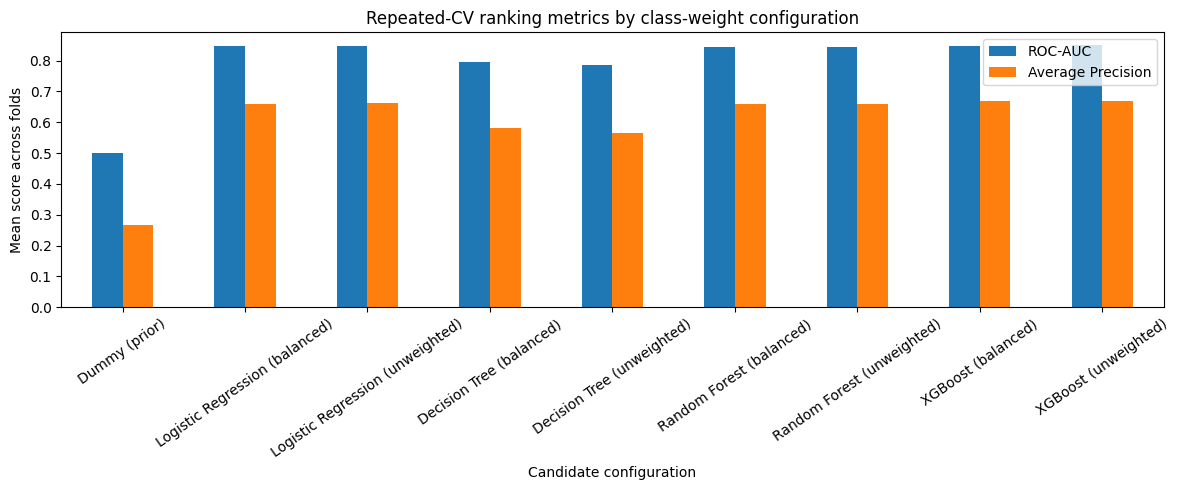

In [7]:
plot_data = summary.set_index("model")[["roc_auc_mean", "average_precision_mean"]]
axis = plot_data.plot(kind="bar", figsize=(12, 5))
axis.set_title("Repeated-CV ranking metrics by class-weight configuration")
axis.set_ylabel("Mean score across folds")
axis.set_xlabel("Candidate configuration")
axis.tick_params(axis="x", rotation=35)
axis.legend(["ROC-AUC", "Average Precision"])
plt.tight_layout()
plt.show()

## 6. Selection stability and interpretation

The repeat winner is the candidate with the highest mean ROC-AUC within each repeat. Winner frequency is descriptive stability evidence, not proof of statistical superiority. A weighted model may increase recall while reducing precision; decide based on the full metric trade-off and the eventual retention use case.

In [8]:
display(imbalance_results["repeat_winners"])
display(imbalance_results["selection_stability"])

print("Interpretation checklist:")
print("1. Did class weighting improve ROC-AUC or Average Precision consistently?")
print("2. Did it increase recall at the cost of precision?")
print("3. Were changes consistent across repeated folds?")
print("4. Is any gain large enough to justify the additional false positives?")
print("5. Do not select a probability threshold here; that is Phase 3.")

,repeat,selected_model,mean_roc_auc
0,1,XGBoost (balanced),0.849222
1,2,XGBoost (unweighted),0.850505
2,3,XGBoost (unweighted),0.847644


,model,winning_repeats,selection_frequency
0,XGBoost (unweighted),2,0.666667
1,XGBoost (balanced),1,0.333333
2,Decision Tree (balanced),0,0.000000
3,Decision Tree (unweighted),0,0.000000
4,Dummy (prior),0,0.000000
5,Logistic Regression (balanced),0,0.000000
6,Logistic Regression (unweighted),0,0.000000
7,Random Forest (balanced),0,0.000000
8,Random Forest (unweighted),0,0.000000


Interpretation checklist:
1. Did class weighting improve ROC-AUC or Average Precision consistently?
2. Did it increase recall at the cost of precision?
3. Were changes consistent across repeated folds?
4. Is any gain large enough to justify the additional false positives?
5. Do not select a probability threshold here; that is Phase 3.


## 7. Save training-only experiment outputs

The generated CSV files are written to the ignored `reports/` directory. They contain only training-CV results and do not replace the frozen Milestone 3–4 baseline.

In [9]:
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
outputs = {
    "phase_2a_imbalance_fold_scores.csv": imbalance_results["fold_scores"],
    "phase_2a_imbalance_summary.csv": summary,
    "phase_2a_imbalance_repeat_winners.csv": imbalance_results["repeat_winners"],
    "phase_2a_imbalance_selection_stability.csv": imbalance_results["selection_stability"],
    "phase_2a_imbalance_paired_differences.csv": paired_differences,
}
for filename, frame in outputs.items():
    frame.to_csv(REPORTS_DIR / filename, index=False)
    print(f"Saved: {REPORTS_DIR / filename}")

Saved: /content/customer-churn-prediction/reports/phase_2a_imbalance_fold_scores.csv
Saved: /content/customer-churn-prediction/reports/phase_2a_imbalance_summary.csv
Saved: /content/customer-churn-prediction/reports/phase_2a_imbalance_repeat_winners.csv
Saved: /content/customer-churn-prediction/reports/phase_2a_imbalance_selection_stability.csv
Saved: /content/customer-churn-prediction/reports/phase_2a_imbalance_paired_differences.csv


## 8. Final protocol checks

Before interpreting the results, confirm the candidate count, number of repeated folds, finite scores and explicit no-test-use flag. Do not copy any metrics into the project report until this notebook has been executed against the original CSV and the outputs have been reviewed.

In [10]:
assert len(candidate_models) == 9
assert len(imbalance_results["fold_scores"]) == 9 * N_SPLITS * N_REPEATS
metric_columns = [
    "roc_auc", "average_precision", "precision", "recall", "f1", "accuracy"
]
assert np.isfinite(
    imbalance_results["fold_scores"][metric_columns].to_numpy()
).all()
assert imbalance_results["configuration"]["test_set_used"] is False
assert set(paired_differences["model_family"]) == {
    "Logistic Regression", "Decision Tree", "Random Forest", "XGBoost"
}
print("All Phase 2A protocol assertions passed.")
print("Training-only CV rows evaluated:", len(imbalance_results["fold_scores"]))
print("Held-out test set used: False")

All Phase 2A protocol assertions passed.
Training-only CV rows evaluated: 135
Held-out test set used: False
